<a href="https://colab.research.google.com/github/Rakshitkumar1/Binary/blob/main/alp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split


In [2]:
dataset=pd.read_csv('/content/Social_Network_Ads.csv')
print(dataset.head())
print('')
print(dataset.shape)

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0

(400, 5)


In [3]:
X1=np.array(dataset.iloc[:,2:4])
y=np.array(dataset.iloc[:,4])
print(X1.shape)
print(y.shape)

(400, 2)
(400,)


In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X2=sc.fit_transform(X1)


In [5]:
x_train,x_test,y_train,y_test=train_test_split(X2,y,test_size=0.25)
print(x_train.shape)
print(x_test.shape)

(300, 2)
(100, 2)


In [31]:
def initialize_params(x_train):
  w1=np.random.randn(5,x_train.shape[1])
  w2=np.random.randn(1,5)

  b1=np.random.randn(5,1)
  b2=np.random.randn(1,1)
  return w1,w2,b1,b2
def sigmoid_act(x):
  s=1/(1+np.exp(-x))
  return s
def forward_path(x,w1,b1,w2,b2):
  z1=np.reshape(np.matmul(w1,x.T),b1.shape)+b1
  A1=sigmoid_act(z1)
  z2 = np. matmul(w2, A1)+b2
  A2 = sigmoid_act(z2)
  return A2,A1
def compute_cost(Y_pred,Y_true):
  cost(Y_true*np.log(Y_pred+(10**-7)))+((1-Y_true)*np.log(1-Y_pred+(10**-7)))
  return -cost
def backward_path(A2,A1,w2,Y,x):
  dz2=(A2-Y)
  dw2=np.matmul(dz2,A1.T)
  db2=dz2.mean(axis=1)
  dA1=np.multiply(dA1,(A1*(1-A1)))
  dw1=dz1*x
  db1=dz1.mean(axis=1)
  return dw1,db1,dw2,db2
def update_params(w,b,dw,db,learning_rate):
  w=w-learning_rate*dw
  db=np.reshape(db,b.shape)
  b=b-learning_rate*db
  return w,b

In [32]:

num_iters = 500
learning_rate = 0.001
his1 = []
w1, w2, b1, b2 = initialize_params(x_train)
for i in range(num_iters):
    cost = 0.0
    for j in range(len(x_train)):
        A2, A1 = forward_path(x_train[j], w1, b1, w2, b2)
        y_pred = A2
        cost+=compute_cost(y_pred,y_train[j])
        dw2,dw1,db2,db1=backward_path(A2,A1,w2,y_train[j],x_train[j])
        w2,b2=update_params(w2,b2,dw2,db2,learning_rate)
        w1,b1=update_params(w1,b1,dw1,db1,learning_rate)
    cost = cost/len(x_train)
    his1.append(cost)

ValueError: operands could not be broadcast together with shapes (1,5) (5,2) 

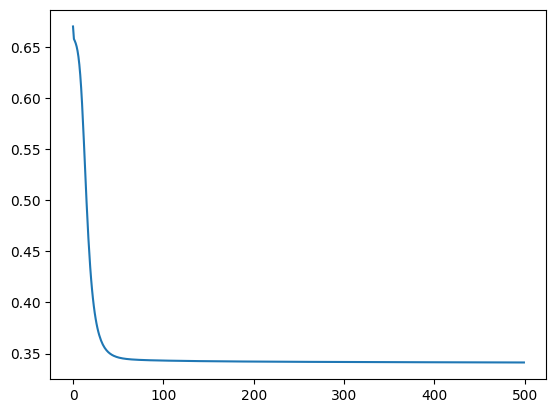

In [34]:
his = np.reshape(np.array(his1), (len(his1)))
plt.plot(his)
plt.show()

In [35]:
print(w1)
print(w1.shape)
print(b1)

[[-1.89927572 -1.06756007]
 [-2.18177026 -1.22978566]
 [-1.11439917 -0.70580896]
 [-1.38899838 -0.80217812]
 [-1.5466085  -0.87740834]]
(5, 2)
[[-0.95904394]
 [-1.18686524]
 [-0.17721814]
 [-0.45879929]
 [-0.62160471]]


In [36]:
print(w2)
print(w2.shape)
print(b2)

[[-2.42161616 -2.72419636 -1.59179573 -1.87701771 -2.04718367]]
(1, 5)
[[2.43445061]]


In [37]:
y_pred=np.zeros(y_test.shape)
for i in range(len(x_test)):
  A2,A1=forward_path(x_test[i],w1,b1,w2,b2)
  A2=np.where(A2>0.5,1,0)
  y_pred[i]=A2
print(y_pred)
print(y_test)

[0. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 1. 1. 0. 0.
 0. 0. 0. 1. 0. 1. 1. 1. 1. 0. 0. 0. 0. 1. 1. 0. 0. 0. 1. 0. 0. 0. 1. 1.
 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0. 1. 0. 0. 0. 1. 0. 1.
 1. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 0.]
[0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 1 0 1 1 1 0 0 0
 1 1 0 0 0 0 1 0 1 1 1 1 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 1 1 1
 0 0 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0]


/tmp/ipykernel_630/597674654.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_pred[i]=A2


In [38]:
print('No. of wong predictions=',sum(y_pred!=y_test))


No. of wong predictions= 10


In [39]:
TP = sum(np.logical_and(y_test==1,y_pred==1))
TN = sum(np.logical_and(y_test==0,y_pred==0))
FP = sum(np.logical_and(y_test==0,y_pred==1))
FN = sum(np.logical_and(y_test==1,y_pred==0))
print('TP, TN, FP, FN = ',TP,TN,FP,FN)
Accuracy = sum(y_pred==y_test)/len(y_test)
print('Accuracy = ',Accuracy)
precision = TP/(TP+FP)
print('Precision = ',precision)
recall = TP/(TP+FN)
print('Recall = ',recall)
f1 = (2*precision*recall)/(precision+recall)
print('Fi-score = ',f1)

TP, TN, FP, FN =  28 62 5 5
Accuracy =  0.9
Precision =  0.8484848484848485
Recall =  0.8484848484848485
Fi-score =  0.8484848484848486


In [40]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score
cm = np.array(confusion_matrix(y_test, y_pred, labels=[0,1]))
print(cm)
print("..")
confusion = pd.DataFrame(cm, index=[ 'Purchased','not purchased'],columns=['purchased','not'])
print(confusion)
print("..")
print(classification_report(y_test, y_pred, labels=[0,1]))
ACC=accuracy_score(y_test, y_pred)
print('Accuracy = ',ACC)

[[62  5]
 [ 5 28]]
..
               purchased  not
Purchased             62    5
not purchased          5   28
..
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        67
           1       0.85      0.85      0.85        33

    accuracy                           0.90       100
   macro avg       0.89      0.89      0.89       100
weighted avg       0.90      0.90      0.90       100

Accuracy =  0.9
